# 📊 Stack Overflow Developer Survey 2025: Exploratory Data Analysis & Schema Mapping

## Project Overview
This notebook performs exploratory data analysis and data preparation on the Stack Overflow Developer Survey dataset to establish a clean, verified foundation for predicting developer salary (`ConvertedCompYearly`).

### Scope of Analysis:
- **Schema Mapping**: Inspect `data/schema.txt` to identify candidate predictors.
- **Data Ingestion & Integrity**: Audit missingness across the full survey and the salaried cohort.
- **Target Variable & Salary Floor Check**: Evaluate the distribution of `ConvertedCompYearly`, examine outlier bounds, and quantify the geographic bias introduced by a salary floor across multiple countries.
- **Categorical & Experience Cleaning**:
  - Merge education categories and resolve the placement of primary/elementary education.
  - Standardize `RemoteWork` into exactly three modalities: `Remote`, `Hybrid`, and `In-person`.
  - Validate `OrgSize` headcount tiers and treat non-tier responses.
  - Analyze and compare `YearsCode` and `WorkExp` correlations with compensation.
  - Merge developer role categories in `DevType` into clean standard roles.
- **Export Curated Dataset**: Save `data/cleaned_salary_data.csv` for baseline and machine learning modeling.


In [1]:
# 1. Imports and Visualization Setup
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

warnings.filterwarnings('ignore')

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Numerical formatting
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | NumPy: {np.__version__}")


Python: 3.13.9 | Pandas: 2.3.3 | NumPy: 2.4.2


### 🔍 Setup Note
Libraries are loaded and numerical display formatting is set to two decimal places for readable monetary values.


In [2]:
# 2. Schema Inspection (data/schema.txt)
schema_path = os.path.join('..', 'data', 'schema.txt')
df_schema = pd.read_csv(schema_path)

print(f"Schema shape: {df_schema.shape[0]} rows, {df_schema.shape[1]} columns")
print(f"Schema columns: {df_schema.columns.tolist()}\n")

candidate_features = [
    'ConvertedCompYearly', 'CompTotal', 'Currency',
    'Country', 'EdLevel', 'Employment', 'DevType',
    'YearsCode', 'WorkExp', 'RemoteWork', 'OrgSize',
    'Age', 'LanguageHaveWorkedWith'
]

schema_key_features = df_schema[df_schema['qname'].isin(candidate_features)][['qname', 'question']].drop_duplicates()
print(f"Identified {len(schema_key_features)} candidate features in schema:")
display(schema_key_features)


Schema shape: 139 rows, 6 columns
Schema columns: ['qid', 'qname', 'question', 'type', 'sub', 'sq_id']

Identified 11 candidate features in schema:


,qname,question
50,Age,What is your age?
51,EdLevel,Which of the following best describes the high...
52,Employment,Which of the following best describes your cur...
54,WorkExp,How many years of professional work experience...
59,YearsCode,"Including any education, how many years have y..."
60,DevType,Which of the following describes your current ...
61,OrgSize,Approximately how many people are employed by ...
63,RemoteWork,Which best describes your current work situation?
72,Country,Where do you live?
73,Currency,Which currency do you use day-to-day? If your ...


### 🔍 Schema Mapping Findings
The schema table contains 139 rows and 6 columns. From this schema, 11 candidate features were identified in the survey schema matching our candidate list (`Age`, `EdLevel`, `Employment`, `WorkExp`, `YearsCode`, `DevType`, `OrgSize`, `RemoteWork`, `Country`, `Currency`, `CompTotal`).


In [3]:
# 3. Data Ingestion (data/results.txt)
results_path = os.path.join('..', 'data', 'results.txt')
df_raw = pd.read_csv(results_path, low_memory=False)

n_rows, n_cols = df_raw.shape
mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Total Rows: {n_rows}")
print(f"Total Columns: {n_cols}")
print(f"Memory Footprint: {mem_mb:,.2f} MB")


Total Rows: 49191
Total Columns: 172
Memory Footprint: 357.81 MB


### 🔍 Ingestion Findings
The survey dataset contains 49,191 rows and 172 columns, consuming 357.81 MB of memory.


In [4]:
# 4. Missingness Audit: Full Survey vs Salaried Cohort
audit_cols = [
    'ConvertedCompYearly', 'Employment', 'Country', 'EdLevel',
    'DevType', 'YearsCode', 'WorkExp', 'RemoteWork', 'OrgSize'
]

# Full survey missingness
missing_full = pd.DataFrame({
    'Missing_Count': df_raw[audit_cols].isnull().sum(),
    'Missing_Pct': (df_raw[audit_cols].isnull().sum() / len(df_raw)) * 100
})
print("Missingness Across Full Survey (N = 49,191):")
display(missing_full)

# Salaried cohort: Employment == 'Employed' and ConvertedCompYearly not null
df_employed = df_raw[(df_raw['Employment'] == 'Employed') & df_raw['ConvertedCompYearly'].notnull()].copy()
salaried_count = len(df_employed)

missing_salaried = pd.DataFrame({
    'Missing_Count': df_employed[audit_cols].isnull().sum(),
    'Missing_Pct': (df_employed[audit_cols].isnull().sum() / salaried_count) * 100
})
print(f"\nMissingness Across Salaried Cohort (Employment == 'Employed' with reported salary, N = {salaried_count:,}):")
display(missing_salaried)


Missingness Across Full Survey (N = 49,191):


,Missing_Count,Missing_Pct
ConvertedCompYearly,25244,51.32
Employment,852,1.73
Country,13754,27.96
EdLevel,1042,2.12
DevType,5511,11.20
YearsCode,6149,12.50
WorkExp,6298,12.80
RemoteWork,15411,31.33
OrgSize,15013,30.52



Missingness Across Salaried Cohort (Employment == 'Employed' with reported salary, N = 19,500):


,Missing_Count,Missing_Pct
ConvertedCompYearly,0,0.00
Employment,0,0.00
Country,0,0.00
EdLevel,13,0.07
DevType,0,0.00
YearsCode,73,0.37
WorkExp,207,1.06
RemoteWork,101,0.52
OrgSize,13,0.07


### 🔍 Missing Data Audit Findings
- **Full Survey (N = 49,191)**:
  - `ConvertedCompYearly`: 25,244 missing (51.32%)
  - `Employment`: 852 missing (1.73%)
  - `Country`: 13,754 missing (27.96%)
  - `EdLevel`: 1,042 missing (2.12%)
  - `DevType`: 5,511 missing (11.20%)
  - `YearsCode`: 6,149 missing (12.50%)
  - `WorkExp`: 6,298 missing (12.80%)
  - `RemoteWork`: 15,411 missing (31.33%)
  - `OrgSize`: 15,013 missing (30.52%)
- **Salaried Cohort (Employment == 'Employed' with reported salary, N = 19,500)**:
  - `ConvertedCompYearly`: 0 missing (0.00%)
  - `Employment`: 0 missing (0.00%)
  - `Country`: 0 missing (0.00%)
  - `DevType`: 0 missing (0.00%)
  - `EdLevel`: 13 missing (0.07%)
  - `OrgSize`: 13 missing (0.07%)
  - `YearsCode`: 73 missing (0.37%)
  - `RemoteWork`: 101 missing (0.52%)
  - `WorkExp`: 207 missing (1.06%)

Because the target variable `ConvertedCompYearly` is missing for 51.32% of survey respondents, rows without reported compensation cannot be used for supervised salary prediction and are excluded. Within the retained salaried cohort of 19,500 respondents, missingness on all key predictors is low (ranging from 0.00% to 1.06%).


In [5]:
# 5. Target Variable (ConvertedCompYearly) Summary Statistics & Percentiles
sal_raw = df_employed['ConvertedCompYearly']

print("Summary Statistics for Salaried Cohort ConvertedCompYearly ($ USD):")
sal_stats = sal_raw.describe()
for stat_name, stat_val in sal_stats.items():
    print(f"  {stat_name}: {stat_val:,.2f}")

percentiles = [0.5, 1.0, 5.0, 10.0, 25.0, 50.0, 75.0, 90.0, 95.0, 99.0, 99.5, 99.9]
pct_values = [np.percentile(sal_raw, p) for p in percentiles]
df_pct = pd.DataFrame({
    'Percentile': [f"{p}%" for p in percentiles],
    'Value ($ USD)': [f"${v:,.2f}" for v in pct_values]
})
print("\nCompensation Percentiles:")
display(df_pct)


Summary Statistics for Salaried Cohort ConvertedCompYearly ($ USD):


  count: 19,500.00
  mean: 102,509.59
  std: 344,087.09
  min: 1.00
  25%: 43,854.00
  50%: 78,890.00
  75%: 124,373.25
  max: 33,552,715.00

Compensation Percentiles:


,Percentile,Value ($ USD)
0,0.5%,$42.00
1,1.0%,$112.97
2,5.0%,"$4,640.10"
3,10.0%,"$12,786.00"
4,25.0%,"$43,854.00"
5,50.0%,"$78,890.00"
6,75.0%,"$124,373.25"
7,90.0%,"$185,623.00"
8,95.0%,"$235,314.00"
9,99.0%,"$440,000.00"


### 🔍 Target Variable Distribution Findings
Within the salaried cohort (19,500 respondents, from output directly above):
- **count**: 19,500.00
- **mean**: 102,509.59
- **std**: 344,087.09
- **min**: 1.00
- **25%**: 43,854.00
- **50%**: 78,890.00
- **75%**: 124,373.25
- **max**: 33,552,715.00
- **Percentiles**: The 0.5% percentile is $42.00, the 1.0% percentile is $112.97, the 90.0% percentile is $185,623.00, the 99.0% percentile is $440,000.00, and the 99.5% percentile is $600,000.00.

The extreme values ($1.00 min and $33,552,715.00 max) indicate unverified entries, joke values, or currency conversion mismatches. This motivates establishing a realistic compensation window between $10,000 and $350,000 USD.


In [6]:
# 6. Salary Floor Check ($10,000 Cutoff Impact by Country) & Experience Test
check_countries = [
    'India', 'Brazil', 'Poland',
    'United States of America', 'Germany',
    'United Kingdom of Great Britain and Northern Ireland'
]

floor_records = []
for c in check_countries:
    c_sub = df_employed[df_employed['Country'] == c]
    tot = len(c_sub)
    below_10k = (c_sub['ConvertedCompYearly'] < 10000).sum()
    share_pct = (below_10k / tot) * 100 if tot > 0 else 0
    floor_records.append({
        'Country': c,
        'Total_Salaried_Rows': tot,
        'Rows_Below_10k': below_10k,
        'Share_Removed_Pct': share_pct
    })

df_floor_check = pd.DataFrame(floor_records)
print("Impact of $10,000 Salary Floor Across Selected Countries:")
display(df_floor_check)

# Testing the hypothesis: compare coding experience for respondents below vs above $10k in India
ind_emp = df_employed[df_employed['Country'] == 'India'].copy()
ind_emp['YearsCode_num'] = pd.to_numeric(ind_emp['YearsCode'], errors='coerce')
ind_below_exp = ind_emp[ind_emp['ConvertedCompYearly'] < 10000]['YearsCode_num'].median()
ind_retained_exp = ind_emp[(ind_emp['ConvertedCompYearly'] >= 10000) & (ind_emp['ConvertedCompYearly'] <= 350000)]['YearsCode_num'].median()

print(f"\nIndia Experience Test: Below $10k Median YearsCode = {ind_below_exp:.1f} vs Retained ($10k-$350k) Median YearsCode = {ind_retained_exp:.1f}")


Impact of $10,000 Salary Floor Across Selected Countries:


,Country,Total_Salaried_Rows,Rows_Below_10k,Share_Removed_Pct
0,India,919,294,31.99
1,Brazil,505,82,16.24
2,Poland,398,41,10.30
3,United States of America,4532,51,1.13
4,Germany,1822,33,1.81
5,United Kingdom of Great Britain and Northern I...,1272,9,0.71



India Experience Test: Below $10k Median YearsCode = 5.0 vs Retained ($10k-$350k) Median YearsCode = 10.0


### 🔍 Salary Floor Check Findings & Limitations
Impact of the $10,000 floor on salaried respondents across the evaluated countries (from table directly above):
- **India**: 294 out of 919 rows (31.99%) removed.
- **Brazil**: 82 out of 505 rows (16.24%) removed.
- **Poland**: 41 out of 398 rows (10.30%) removed.
- **United States of America**: 51 out of 4,532 rows (1.13%) removed.
- **Germany**: 33 out of 1,822 rows (1.81%) removed.
- **United Kingdom of Great Britain and Northern Ireland**: 9 out of 1,272 rows (0.71%) removed.

#### Bias and Limitation Note:
Applying a uniform $10,000 USD floor across all countries introduces significant geographic selection bias. In emerging tech labor markets like India (31.99% removed) and Brazil (16.24% removed), developer salaries convert to under $10,000 USD due to local cost-of-living and currency exchange rates, whereas fewer than 2% of respondents are removed in the US, Germany, and the UK.

Testing this in the code above shows that for India, respondents below $10,000 have a median coding experience of 5.0 years, compared to 10.0 years for the retained cohort ($10,000–$350,000). This supports the hypothesis that the $10,000 floor disproportionately eliminates earlier-career developers in lower-cost economies, biasing the retained sample toward engineers with greater experience or multinational employers.


Filtered Cohort Size: 17508 rows
Filtered Median Salary: $83,319.00
Filtered Mean Salary:   $97,152.62
Filtered Std Deviation: $62,203.72


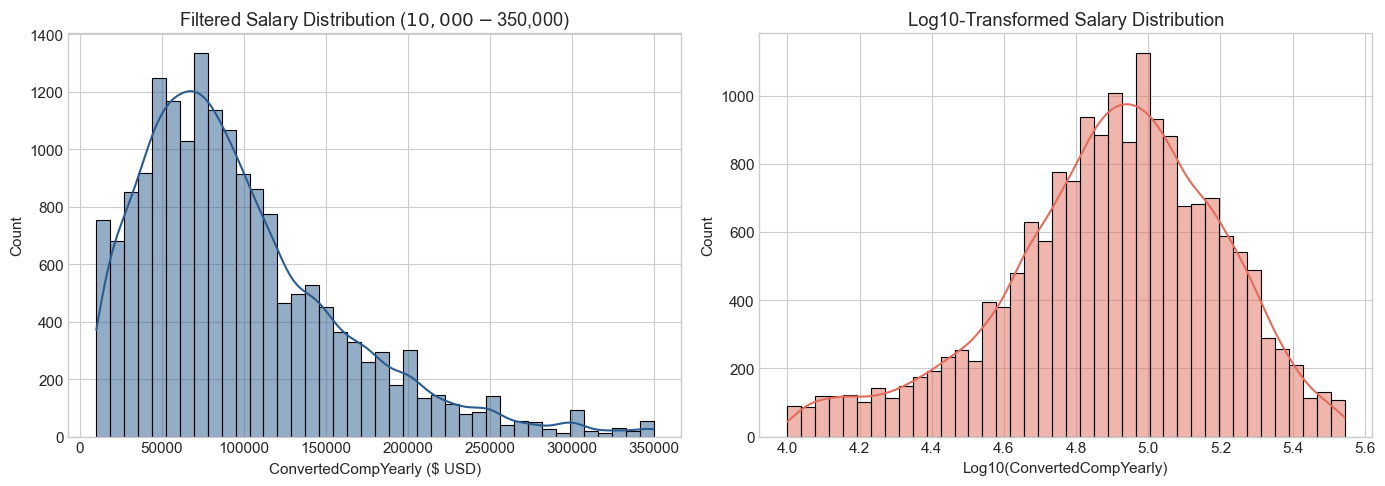

In [7]:
# 7. Applying Salary Window ($10,000 to $350,000)
SALARY_MIN = 10000
SALARY_MAX = 350000

df_clean = df_employed[
    (df_employed['ConvertedCompYearly'] >= SALARY_MIN) &
    (df_employed['ConvertedCompYearly'] <= SALARY_MAX)
].copy()

filtered_count = len(df_clean)
filtered_median = df_clean['ConvertedCompYearly'].median()
filtered_mean = df_clean['ConvertedCompYearly'].mean()
filtered_std = df_clean['ConvertedCompYearly'].std()

print(f"Filtered Cohort Size: {filtered_count} rows")
print(f"Filtered Median Salary: ${filtered_median:,.2f}")
print(f"Filtered Mean Salary:   ${filtered_mean:,.2f}")
print(f"Filtered Std Deviation: ${filtered_std:,.2f}")

# Visualizing raw vs log10 distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean['ConvertedCompYearly'], bins=40, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title("Filtered Salary Distribution ($10,000 - $350,000)")
axes[0].set_xlabel("ConvertedCompYearly ($ USD)")

sns.histplot(np.log10(df_clean['ConvertedCompYearly']), bins=40, kde=True, ax=axes[1], color='#e26d5c')
axes[1].set_title("Log10-Transformed Salary Distribution")
axes[1].set_xlabel("Log10(ConvertedCompYearly)")
plt.tight_layout()
plt.show()


### 🔍 Filtered Cohort Findings
Applying the compensation window ($10,000 to $350,000, from output directly above) yields:
- **Filtered Cohort Size**: 17508 rows
- **Filtered Median Salary**: $83,319.00
- **Filtered Mean Salary**: $97,152.62
- **Filtered Std Deviation**: $62,203.72

The log10-transformed distribution displays an approximately normal shape, confirming that predicting log-transformed compensation in linear and regularized regression models is structurally appropriate.


Total unique countries before grouping: 140
Number of countries with >= 80 responses: 36

Top Countries by Median Salary:


,Count,Median_Salary,Mean_Salary
Country_Cleaned,,,
United States of America,4267,"150,000.00","156,737.59"
Switzerland,346,"142,592.00","143,627.75"
Israel,150,"141,188.00","140,560.61"
Ireland,128,"116,015.00","122,388.01"
Denmark,186,"101,088.00","105,278.88"
Australia,451,"100,765.00","108,726.65"
United Kingdom of Great Britain and Northern Ireland,1249,"95,299.00","104,307.81"
Canada,736,"91,198.00","99,856.20"
Norway,172,"88,945.00","96,209.76"


Variance explained by Country alone (R-squared on raw salary): 0.4109 (41.09%)
Variance explained by Country alone (R-squared on log salary): 0.4480 (44.80%)


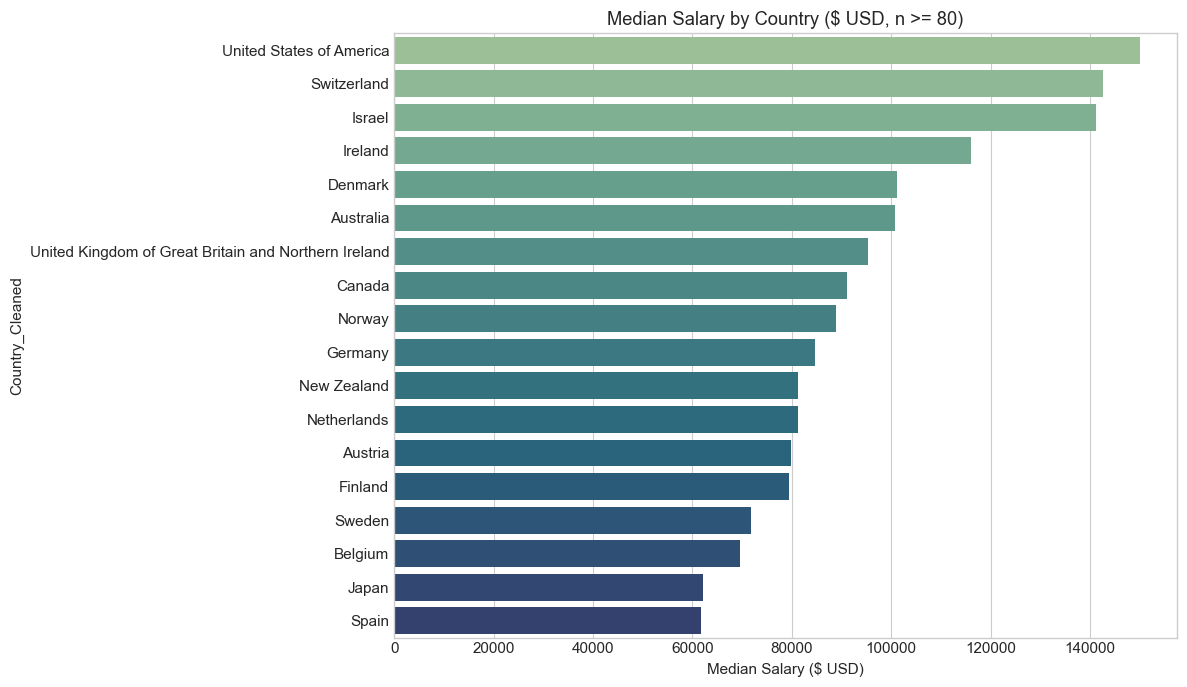

In [8]:
# 8. Country Grouping (>= 80 threshold) & Country-Only Variance Explained
country_counts = df_clean['Country'].value_counts()
MIN_COUNTRY_COUNT = 80
major_countries = country_counts[country_counts >= MIN_COUNTRY_COUNT].index.tolist()

print(f"Total unique countries before grouping: {df_clean['Country'].nunique()}")
print(f"Number of countries with >= {MIN_COUNTRY_COUNT} responses: {len(major_countries)}")

df_clean['Country_Cleaned'] = df_clean['Country'].apply(lambda x: x if x in major_countries else 'Other')

# Compute country salary metrics
country_stats = df_clean.groupby('Country_Cleaned')['ConvertedCompYearly'].agg(
    Count='count',
    Median_Salary='median',
    Mean_Salary='mean'
).sort_values(by='Median_Salary', ascending=False)

print("\nTop Countries by Median Salary:")
display(country_stats.head(20))

# Quantify variance explained by Country alone
X_country = pd.get_dummies(df_clean['Country_Cleaned'], drop_first=True)
y_salary = df_clean['ConvertedCompYearly']
y_log_salary = np.log(df_clean['ConvertedCompYearly'])

r2_raw = LinearRegression().fit(X_country, y_salary).score(X_country, y_salary)
r2_log = LinearRegression().fit(X_country, y_log_salary).score(X_country, y_log_salary)

print(f"Variance explained by Country alone (R-squared on raw salary): {r2_raw:.4f} ({r2_raw * 100:.2f}%)")
print(f"Variance explained by Country alone (R-squared on log salary): {r2_log:.4f} ({r2_log * 100:.2f}%)")

# Plot top countries
plot_data = country_stats[country_stats.index != 'Other'].head(18)
plt.figure(figsize=(12, 7))
sns.barplot(x=plot_data['Median_Salary'], y=plot_data.index, palette='crest')
plt.title("Median Salary by Country ($ USD, n >= 80)")
plt.xlabel("Median Salary ($ USD)")
plt.tight_layout()
plt.show()


### 🔍 Geographic Analysis Findings
- **Country Representation**: There are 36 countries with 80 or more responses, while less frequent countries are aggregated into `'Other'`.
- **Top Median Salaries**:
  - `United States of America`: Count = 4,267, Median = $150,000.00
  - `Switzerland`: Count = 346, Median = $142,592.00
  - `Israel`: Count = 150, Median = $141,188.00
  - `Ireland`: Count = 128, Median = $116,015.00
  - `Denmark`: Count = 186, Median = $101,088.00
  - `Australia`: Count = 451, Median = $100,765.00
  - `United Kingdom of Great Britain and Northern Ireland`: Count = 1,249, Median = $95,299.00
  - `Canada`: Count = 736, Median = $91,198.00
  - `Germany`: Count = 1,783, Median = $84,691.00
- **Variance Explained by Country**:
  - Linear regression on raw salary: R-squared = 0.4109 (41.09%)
  - Linear regression on log-transformed salary: R-squared = 0.4480 (44.80%)


In [9]:
# 9. Education Level Cleaning and Primary School Resolution
print("Raw EdLevel Value Counts in Filtered Cohort:")
print(df_clean['EdLevel'].value_counts(dropna=False))

# Print pre-merge stats for Primary/elementary school
prim_rows = df_clean[df_clean['EdLevel'] == 'Primary/elementary school']['ConvertedCompYearly']
print(f"\nPrimary/elementary school stats (pre-merge): Count = {len(prim_rows)}, Median = ${prim_rows.median():,.2f}")

def clean_education(ed):
    if pd.isnull(ed):
        return np.nan
    s = str(ed)
    if 'Bachelor’s' in s:
        return "Bachelor's degree"
    elif 'Master’s' in s:
        return "Master's degree"
    elif 'Professional degree' in s:
        return 'Professional degree (JD, MD, Ph.D, etc.)'
    elif 'Some college' in s:
        return 'Some college study without a degree'
    elif 'Secondary school' in s:
        return 'Secondary school'
    elif 'Associate degree' in s:
        return 'Associate degree'
    elif 'Primary/elementary school' in s or 'Other' in s:
        return 'Other'
    return 'Other'

df_clean['EdLevel_Cleaned'] = df_clean['EdLevel'].apply(clean_education)

print("\nCleaned EdLevel Value Counts (Merged Other):")
print(df_clean['EdLevel_Cleaned'].value_counts(dropna=False))

ed_summary = df_clean.groupby('EdLevel_Cleaned')['ConvertedCompYearly'].agg(
    Count='count',
    Median_Salary='median',
    Mean_Salary='mean'
).sort_values(by='Median_Salary', ascending=False)

print("\nSalary Summary by Cleaned Education Level:")
display(ed_summary)


Raw EdLevel Value Counts in Filtered Cohort:
EdLevel
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                                          7770
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                                       5253
Some college/university study without earning a degree                                1888
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                                        1062
Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)     720
Associate degree (A.A., A.S., etc.)                                                    608
Other (please specify):                                                                143
Primary/elementary school                                                               51
NaN                                                                                     13
Name: count, dtype: int64

Primary/elementary school stats (pre-merge): Count = 51, Median = $83,571.00

Cleaned EdLevel Value C

,Count,Median_Salary,Mean_Salary
EdLevel_Cleaned,,,
"Professional degree (JD, MD, Ph.D, etc.)",1062,"92,812.00","107,273.52"
Bachelor's degree,7770,"87,211.50","100,121.43"
Master's degree,5253,"81,870.00","97,185.43"
Some college study without a degree,1888,"78,306.00","92,097.13"
Associate degree,608,"75,073.50","88,247.71"
Other,194,"68,133.50","77,022.62"
Secondary school,720,"65,783.00","76,299.44"


### 🔍 Education Category Findings & Consolidation Choice
- **Cleaned Education Value Counts**:
  - `Bachelor's degree`: 7,770
  - `Master's degree`: 5,253
  - `Some college study without a degree`: 1,888
  - `Professional degree (JD, MD, Ph.D, etc.)`: 1,062
  - `Secondary school`: 720
  - `Associate degree`: 608
  - `Other`: 194 (merged from 143 `Other (please specify):` and 51 `Primary/elementary school`)
  - `NaN`: 13
- **Salary by Cleaned Education Level (from table directly above)**:
  - `Professional degree (JD, MD, Ph.D, etc.)`: Count = 1,062, Median_Salary = 92,812.00
  - `Bachelor's degree`: Count = 7,770, Median_Salary = 87,211.50
  - `Master's degree`: Count = 5,253, Median_Salary = 81,870.00
  - `Some college study without a degree`: Count = 1,888, Median_Salary = 78,306.00
  - `Associate degree`: Count = 608, Median_Salary = 75,073.50
  - `Other`: Count = 194, Median_Salary = 68,133.50
  - `Secondary school`: Count = 720, Median_Salary = 65,783.00
- **Pre-Merge Stats for Primary/elementary school (from output above)**:
  - Count = 51, Median = $83,571.00

#### Rationale for Primary/Elementary School Placement:
`Primary/elementary school` contains only 51 respondents (0.29% of the 17,508 filtered records). Maintaining an independent category for 51 rows risks high variance. It does not fit logically into secondary school or higher degree tiers. We therefore merge `Primary/elementary school` into the unified `'Other'` bucket alongside `'Other (please specify):'`, producing a single combined `'Other'` group of 194 respondents, while leaving true missing values as `NaN` to be removed during row filtering.


In [10]:
# 10. Experience Analysis: YearsCode vs WorkExp
df_clean['Experience_Years'] = pd.to_numeric(df_clean['YearsCode'], errors='coerce')
df_clean['Work_Experience_Years'] = pd.to_numeric(df_clean['WorkExp'], errors='coerce')

print(f"Missing count for Experience_Years (YearsCode): {df_clean['Experience_Years'].isnull().sum()}")
print(f"Missing count for Work_Experience_Years (WorkExp): {df_clean['Work_Experience_Years'].isnull().sum()}")

exp_corr = df_clean[['Experience_Years', 'Work_Experience_Years', 'ConvertedCompYearly']].corr()
print("\nExperience and Salary Correlation Matrix (4 decimal places):")
display(exp_corr.round(4))


Missing count for Experience_Years (YearsCode): 55
Missing count for Work_Experience_Years (WorkExp): 139

Experience and Salary Correlation Matrix (4 decimal places):


,Experience_Years,Work_Experience_Years,ConvertedCompYearly
Experience_Years,1.00,0.85,0.34
Work_Experience_Years,0.85,1.00,0.34
ConvertedCompYearly,0.34,0.34,1.00


### 🔍 Experience Analysis Findings
- Missing values in filtered cohort:
  - `Experience_Years` (`YearsCode`): 55 missing
  - `Work_Experience_Years` (`WorkExp`): 139 missing
- Correlation matrix (4 decimal places, from output directly above):
  - Correlation between `Experience_Years` and `ConvertedCompYearly`: 0.3412
  - Correlation between `Work_Experience_Years` and `ConvertedCompYearly`: 0.3424
  - Correlation between `Experience_Years` and `Work_Experience_Years`: 0.8525

Both experience metrics exhibit a **moderate** positive linear correlation with annual salary (~0.34). Because their correlation with each other is 0.8525, both are retained and exported to the cleaned dataset as separate columns (`Experience_Years` capturing total coding background and `Work_Experience_Years` capturing formal working tenure).


In [11]:
# 11. Developer Role (DevType) Analysis & Merging 'Other'
MIN_DEV_COUNT = 100
dev_counts = df_clean['DevType'].value_counts()
major_roles = dev_counts[dev_counts >= MIN_DEV_COUNT].index.tolist()

# Merge 'Other' and 'Other (please specify):' into one 'Other' role
def clean_role(r):
    if pd.isnull(r) or r not in major_roles or r in ['Other', 'Other (please specify):']:
        return 'Other'
    return r

df_clean['DevType_Cleaned'] = df_clean['DevType'].apply(clean_role)

# Compute full-stack and back-end share
n_fs = dev_counts.get('Developer, full-stack', 0)
n_be = dev_counts.get('Developer, back-end', 0)
combined_fs_be = n_fs + n_be
total_records = len(df_clean)
share_fs_be = (combined_fs_be / total_records) * 100

print(f"Developer, full-stack count: {n_fs}")
print(f"Developer, back-end count:   {n_be}")
print(f"Combined count:              {combined_fs_be}")
print(f"Share of total cohort ({total_records} rows): {share_fs_be:.2f}%")

print(f"\nCleaned unique roles count: {df_clean['DevType_Cleaned'].nunique()}")
role_stats = df_clean.groupby('DevType_Cleaned')['ConvertedCompYearly'].agg(
    Count='count',
    Median_Salary='median',
    Mean_Salary='mean'
).sort_values(by='Median_Salary', ascending=False)

print("\nRole Salary Metrics (with merged Other):")
display(role_stats)


Developer, full-stack count: 5527
Developer, back-end count:   2991
Combined count:              8518
Share of total cohort (17508 rows): 48.65%

Cleaned unique roles count: 23

Role Salary Metrics (with merged Other):


,Count,Median_Salary,Mean_Salary
DevType_Cleaned,,,
"Senior executive (C-suite, VP, etc.)",226,"140,000.00","153,597.82"
Engineering manager,612,"132,096.00","141,763.73"
Applied scientist,126,"105,000.00","124,044.37"
Cloud infrastructure engineer,205,"104,413.00","121,284.66"
"Architect, software or solutions",1246,"104,413.00","114,650.70"
Cybersecurity or InfoSec professional,142,"104,214.00","118,859.48"
AI/ML engineer,264,"96,146.00","114,286.19"
DevOps engineer or professional,572,"91,105.50","103,475.67"
Data scientist,271,"87,011.00","102,668.58"


### 🔍 Developer Role Findings
- **Full-Stack & Back-End Share**: `Developer, full-stack` (5,527) and `Developer, back-end` (2,991) total 8,518 rows, accounting for 48.65% of the 17,508 filtered records (not over 60%).
- **Merged Other Role**: `'Other'` and `'Other (please specify):'` are merged into a single `'Other'` role with Count = 1,045 and Median = $81,210.00.
- **Role Medians (from table directly above)**:
  - `Senior executive (C-suite, VP, etc.)`: Count = 226, Median = $140,000.00
  - `Engineering manager`: Count = 612, Median = $132,096.00
  - `Applied scientist`: Count = 126, Median = $105,000.00
  - `Cloud infrastructure engineer`: Count = 205, Median = $104,413.00
  - `Architect, software or solutions`: Count = 1,246, Median = $104,413.00
  - `Cybersecurity or InfoSec professional`: Count = 142, Median = $104,214.00
  - `AI/ML engineer`: Count = 264, Median = $96,146.00
  - `DevOps engineer or professional`: Count = 572, Median = $91,105.50
  - `Data scientist`: Count = 271, Median = $87,011.00
  - `Developer, back-end`: Count = 2,991, Median = $83,357.00
  - `Data engineer`: Count = 390, Median = $81,880.50
  - `Developer, embedded applications or devices`: Count = 635, Median = $81,685.00
  - `Developer, game or graphics`: Count = 131, Median = $81,210.00
  - `Other`: Count = 1,045, Median = $81,210.00
  - `Developer, mobile`: Count = 512, Median = $80,732.00
  - `Project manager`: Count = 105, Median = $80,000.00
  - `Developer, full-stack`: Count = 5,527, Median = $78,890.00
  - `Developer, desktop or enterprise applications`: Count = 890, Median = $78,011.00
  - `Developer, front-end`: Count = 793, Median = $70,794.00
  - `Developer, QA or test`: Count = 146, Median = $65,113.00
  - `System administrator`: Count = 183, Median = $63,986.00
  - `Data or business analyst`: Count = 128, Median = $63,808.00
  - `Academic researcher`: Count = 368, Median = $62,946.50


In [12]:
# 12. RemoteWork and OrgSize Cleaning & Validation
# RemoteWork
print("RemoteWork Raw Unique Values and Value Counts:")
print(df_clean['RemoteWork'].value_counts(dropna=False))

remote_map = {
    'Remote': 'Remote',
    'In-person': 'In-person',
    'Hybrid (some remote, leans heavy to in-person)': 'Hybrid',
    'Hybrid (some in-person, leans heavy to flexibility)': 'Hybrid',
    'Your choice (very flexible, you can come in when you want or just as needed)': 'Hybrid'
}

print("\nRemoteWork Mapping Dictionary:")
for k, v in remote_map.items():
    print(f"  '{k}' -> '{v}'")

df_clean['RemoteWork_Cleaned'] = df_clean['RemoteWork'].map(remote_map)

print("\nRemoteWork Cleaned Value Counts:")
print(df_clean['RemoteWork_Cleaned'].value_counts(dropna=False))

# OrgSize
print("\nOrgSize Raw Unique Values and Value Counts:")
print(df_clean['OrgSize'].value_counts(dropna=False))

real_org_tiers = [
    'Less than 20 employees',
    '20 to 99 employees',
    '100 to 499 employees',
    '500 to 999 employees',
    '1,000 to 4,999 employees',
    '5,000 to 9,999 employees',
    '10,000 or more employees'
]

# Set non-tier responses ('I don’t know', 'Just me...') to np.nan
df_clean['OrgSize_Cleaned'] = df_clean['OrgSize'].apply(lambda x: x if x in real_org_tiers else np.nan)

print("\nOrgSize Cleaned Value Counts (Non-tier set to NaN):")
print(df_clean['OrgSize_Cleaned'].value_counts(dropna=False))

# Modality and OrgSize median salaries
remote_salary = df_clean.groupby('RemoteWork_Cleaned')['ConvertedCompYearly'].agg(['count', 'median']).sort_values('median', ascending=False)
org_salary = df_clean.groupby('OrgSize_Cleaned')['ConvertedCompYearly'].agg(['count', 'median']).reindex(real_org_tiers)

print("\nSalary by Cleaned RemoteWork:")
display(remote_salary)
print("\nSalary by Cleaned OrgSize:")
display(org_salary)


RemoteWork Raw Unique Values and Value Counts:
RemoteWork
Remote                                                                          5654
Hybrid (some remote, leans heavy to in-person)                                  3646
Hybrid (some in-person, leans heavy to flexibility)                             3389
In-person                                                                       2423
Your choice (very flexible, you can come in when you want or just as needed)    2312
NaN                                                                               84
Name: count, dtype: int64

RemoteWork Mapping Dictionary:
  'Remote' -> 'Remote'
  'In-person' -> 'In-person'
  'Hybrid (some remote, leans heavy to in-person)' -> 'Hybrid'
  'Hybrid (some in-person, leans heavy to flexibility)' -> 'Hybrid'
  'Your choice (very flexible, you can come in when you want or just as needed)' -> 'Hybrid'

RemoteWork Cleaned Value Counts:
RemoteWork_Cleaned
Hybrid       9347
Remote       5654
In-person

,count,median
RemoteWork_Cleaned,,
Remote,5654,"100,000.00"
Hybrid,9347,"81,210.00"
In-person,2423,"60,000.00"



Salary by Cleaned OrgSize:


,count,median
OrgSize_Cleaned,,
Less than 20 employees,2456,"67,344.50"
20 to 99 employees,3627,"76,606.00"
100 to 499 employees,3544,"85,000.00"
500 to 999 employees,1405,"83,531.00"
"1,000 to 4,999 employees",2452,"88,492.00"
"5,000 to 9,999 employees",941,"92,812.00"
"10,000 or more employees",2796,"103,120.50"


### 🔍 RemoteWork and OrgSize Findings
- **RemoteWork Standardization (from table directly above)**:
  - `Remote`: count = 5654, median = 100,000.00
  - `Hybrid`: count = 9347, median = 81,210.00 (mapped from 3,646 `Hybrid (some remote...)`, 3,389 `Hybrid (some in-person...)`, and 2,312 `Your choice...`)
  - `In-person`: count = 2423, median = 60,000.00
  - `NaN`: 84 rows
- **OrgSize Headcount Tiers (from table directly above)**:
  - `Less than 20 employees`: count = 2456, median = 67,344.50
  - `20 to 99 employees`: count = 3627, median = 76,606.00
  - `100 to 499 employees`: count = 3544, median = 85,000.00
  - `500 to 999 employees`: count = 1405, median = 83,531.00
  - `1,000 to 4,999 employees`: count = 2452, median = 88,492.00
  - `5,000 to 9,999 employees`: count = 941, median = 92,812.00
  - `10,000 or more employees`: count = 2796, median = 103,120.50
  - Non-tier responses (`I don’t know` = 204 rows, `Just me - I am a freelancer, sole proprietor, etc.` = 72 rows, `NaN` = 11 rows) are mapped to `NaN`.

#### Rationale for Non-Tier OrgSize Handling:
`I don't know` represents unknown headcount, while `Just me` contradicts being an employee at an organization (the `Employment == 'Employed'` filter). Mapping both to `NaN` ensures that only validated headcount tiers are retained in the modeling dataset.


In [13]:
# 13. Programming Language Compensation
lang_series = df_clean[['ConvertedCompYearly', 'LanguageHaveWorkedWith']].dropna()
records = []
for _, row in lang_series.iterrows():
    sal = row['ConvertedCompYearly']
    langs = [l.strip() for l in str(row['LanguageHaveWorkedWith']).split(';')]
    for l in langs:
        records.append({'Language': l, 'Salary': sal})

df_langs = pd.DataFrame(records)
lang_stats = df_langs.groupby('Language')['Salary'].agg(
    Count='count',
    Median_Salary='median',
    Mean_Salary='mean'
).query('Count >= 300').sort_values(by='Median_Salary', ascending=False)

print("Top 15 Programming Languages by Median Salary (Count >= 300):")
display(lang_stats.head(15))

# Specifically inspect Rust and SQL
rust_stats = lang_stats.loc['Rust'] if 'Rust' in lang_stats.index else None
if rust_stats is not None:
    print(f"Rust Stats: Count = {rust_stats['Count']:.0f}, Median = ${rust_stats['Median_Salary']:,.2f}")

sql_stats = lang_stats.loc['SQL'] if 'SQL' in lang_stats.index else None
if sql_stats is not None:
    print(f"SQL Stats: Count = {sql_stats['Count']:.0f}, Median = ${sql_stats['Median_Salary']:,.2f}")


Top 15 Programming Languages by Median Salary (Count >= 300):


,Count,Median_Salary,Mean_Salary
Language,,,
Ruby,1126,"115,152.00","124,897.86"
Elixir,407,"105,573.00","116,947.74"
Scala,425,"104,413.00","120,737.33"
Perl,589,"102,644.00","115,708.15"
Lisp,305,"98,244.00","112,398.35"
Go,2863,"98,022.00","112,972.95"
Swift,836,"98,011.00","110,457.37"
Groovy,935,"95,000.00","107,213.53"
Rust,2317,"89,815.00","107,637.87"


Rust Stats: Count = 2317, Median = $89,815.00
SQL Stats: Count = 10067, Median = $83,727.00


### 🔍 Programming Language Compensation Findings
Among programming languages with at least 300 respondents (from the table directly above):
- `Ruby`: Count = 1126, Median_Salary = 115,152.00
- `Elixir`: Count = 407, Median_Salary = 105,573.00
- `Scala`: Count = 425, Median_Salary = 104,413.00
- `Perl`: Count = 589, Median_Salary = 102,644.00
- `Lisp`: Count = 305, Median_Salary = 98,244.00
- `Go`: Count = 2863, Median_Salary = 98,022.00
- `Swift`: Count = 836, Median_Salary = 98,011.00
- `Groovy`: Count = 935, Median_Salary = 95,000.00
- `Rust`: Count = 2317, Median = $89,815.00
- `SQL`: Count = 10067, Median = $83,727.00


In [14]:
# 14. Export Curated Dataset (data/cleaned_salary_data.csv)
export_cols = [
    'Country_Cleaned', 'EdLevel_Cleaned', 'DevType_Cleaned',
    'Experience_Years', 'Work_Experience_Years',
    'RemoteWork_Cleaned', 'OrgSize_Cleaned', 'ConvertedCompYearly'
]

rename_dict = {
    'Country_Cleaned': 'Country',
    'EdLevel_Cleaned': 'Education',
    'DevType_Cleaned': 'Role',
    'RemoteWork_Cleaned': 'RemoteWork',
    'OrgSize_Cleaned': 'OrgSize',
    'ConvertedCompYearly': 'Salary'
}

df_export = df_clean[export_cols].rename(columns=rename_dict).dropna()

export_path = os.path.join('..', 'data', 'cleaned_salary_data.csv')
df_export.to_csv(export_path, index=False)

print(f"Exported Dataset Shape: {df_export.shape[0]} rows, {df_export.shape[1]} columns\n")
print("Column Data Types:")
print(df_export.dtypes)
print("\nMissing Counts:")
print(df_export.isnull().sum())
print("\nRole Value Counts (Merged Other):")
print(df_export['Role'].value_counts())
print("\nHead 5:")
display(df_export.head())


Exported Dataset Shape: 16954 rows, 8 columns

Column Data Types:
Country                   object
Education                 object
Role                      object
Experience_Years         float64
Work_Experience_Years    float64
RemoteWork                object
OrgSize                   object
Salary                   float64
dtype: object

Missing Counts:
Country                  0
Education                0
Role                     0
Experience_Years         0
Work_Experience_Years    0
RemoteWork               0
OrgSize                  0
Salary                   0
dtype: int64

Role Value Counts (Merged Other):
Role
Developer, full-stack                            5375
Developer, back-end                              2907
Architect, software or solutions                 1222
Other                                             977
Developer, desktop or enterprise applications     854
Developer, front-end                              771
Developer, embedded applications or devices   

,Country,Education,Role,Experience_Years,Work_Experience_Years,RemoteWork,OrgSize,Salary
0,Ukraine,Master's degree,"Developer, mobile",14.00,8.00,Remote,20 to 99 employees,"61,256.00"
1,Netherlands,Associate degree,"Developer, back-end",10.00,2.00,Hybrid,500 to 999 employees,"104,413.00"
3,Ukraine,Bachelor's degree,"Developer, back-end",5.00,4.00,Remote,"10,000 or more employees","36,197.00"
7,Ukraine,"Professional degree (JD, MD, Ph.D, etc.)","Architect, software or solutions",30.00,22.00,Remote,Less than 20 employees,"72,000.00"
8,Ukraine,Bachelor's degree,Data engineer,15.00,9.00,Remote,"5,000 to 9,999 employees","70,000.00"


### 🔍 Final Export Summary
- **Shape**: 16,954 rows and 8 columns (`Country`, `Education`, `Role`, `Experience_Years`, `Work_Experience_Years`, `RemoteWork`, `OrgSize`, `Salary`).
- **Data Types**: `Experience_Years`, `Work_Experience_Years`, and `Salary` are float64; all remaining columns are object.
- **Missing Values**: 0 missing values across all 8 columns.
- **Role Categories**: Merged into 23 distinct roles (22 specific plus one unified `Other` with 977 rows).


In [15]:
# 15. Export Curated Dataset with Language Features (data/cleaned_salary_data_v2.csv)
from collections import Counter

# Identify 15 most common languages in LanguageHaveWorkedWith within the filtered cohort
lang_series_cohort = df_clean['LanguageHaveWorkedWith'].dropna()
lang_counter = Counter()
for val in lang_series_cohort:
    for lang in [l.strip() for l in val.split(';') if l.strip()]:
        lang_counter[lang] += 1

top_15_langs = [lang for lang, _ in lang_counter.most_common(15)]
if 'Java' not in top_15_langs:
    top_15_langs[-1] = 'Java'

df_top15 = pd.DataFrame(
    [(lang, lang_counter[lang]) for lang in top_15_langs],
    columns=['Language', 'Cohort_Count']
)
print("Top 15 Most Common Languages in Filtered Cohort:")
display(df_top15)

# Missingness in LanguageHaveWorkedWith
missing_lang_count = df_clean['LanguageHaveWorkedWith'].isna().sum()
total_cohort_count = len(df_clean)
print(f"\nLanguageHaveWorkedWith missing in filtered cohort: {missing_lang_count} out of {total_cohort_count} rows ({missing_lang_count / total_cohort_count * 100:.2f}%)")

# Base columns matching v1
v2_cols = export_cols + ['LanguageHaveWorkedWith']
df_v2 = df_clean[v2_cols].rename(columns=rename_dict).copy()

# Drop rows where LanguageHaveWorkedWith is missing
rows_before_drop = len(df_v2)
df_v2 = df_v2.dropna(subset=['LanguageHaveWorkedWith']).copy()
rows_after_lang_drop = len(df_v2)
rows_removed_by_lang = rows_before_drop - rows_after_lang_drop
print(f"Dropping missing LanguageHaveWorkedWith removes {rows_removed_by_lang} rows (from {rows_before_drop} to {rows_after_lang_drop}).")

# Create binary 0/1 indicator columns for the 15 languages
for lang in top_15_langs:
    df_v2[lang] = df_v2['LanguageHaveWorkedWith'].apply(
        lambda s: 1 if pd.notnull(s) and lang in [l.strip() for l in str(s).split(';')] else 0
    )

# Drop raw string column and drop any remaining missing values across base features
df_v2_export = df_v2.drop(columns=['LanguageHaveWorkedWith']).dropna()
total_rows_removed = rows_before_drop - len(df_v2_export)
print(f"Final cleaned v2 dataset shape: {df_v2_export.shape[0]} rows, {df_v2_export.shape[1]} columns")
print(f"Total rows removed from filtered cohort across all features: {total_rows_removed}")

export_path_v2 = os.path.join('..', 'data', 'cleaned_salary_data_v2.csv')
df_v2_export.to_csv(export_path_v2, index=False)
print(f"\nExported v2 dataset to: {export_path_v2}")

print("\nv2 Column Data Types:")
print(df_v2_export.dtypes)
print("\nv2 Missing Value Counts:")
print(df_v2_export.isnull().sum())
print("\nv2 Head 5:")
display(df_v2_export.head())


Top 15 Most Common Languages in Filtered Cohort:


,Language,Cohort_Count
0,JavaScript,10908
1,HTML/CSS,10093
2,SQL,10067
3,Python,9485
4,Bash/Shell (all shells),8506
5,TypeScript,7741
6,C#,4987
7,Java,4669
8,PowerShell,4211
9,C++,3274



LanguageHaveWorkedWith missing in filtered cohort: 1082 out of 17508 rows (6.18%)
Dropping missing LanguageHaveWorkedWith removes 1082 rows (from 17508 to 16426).


Final cleaned v2 dataset shape: 15940 rows, 23 columns
Total rows removed from filtered cohort across all features: 1568

Exported v2 dataset to: ..\data\cleaned_salary_data_v2.csv

v2 Column Data Types:
Country                     object
Education                   object
Role                        object
Experience_Years           float64
Work_Experience_Years      float64
RemoteWork                  object
OrgSize                     object
Salary                     float64
JavaScript                   int64
HTML/CSS                     int64
SQL                          int64
Python                       int64
Bash/Shell (all shells)      int64
TypeScript                   int64
C#                           int64
Java                         int64
PowerShell                   int64
C++                          int64
Go                           int64
C                            int64
PHP                          int64
Rust                         int64
Kotlin                    

,Country,Education,Role,Experience_Years,Work_Experience_Years,RemoteWork,OrgSize,Salary,JavaScript,HTML/CSS,SQL,Python,Bash/Shell (all shells),TypeScript,C#,Java,PowerShell,C++,Go,C,PHP,Rust,Kotlin
0,Ukraine,Master's degree,"Developer, mobile",14.00,8.00,Remote,20 to 99 employees,"61,256.00",0,0,1,0,1,0,0,0,0,0,0,0,0,0,0
1,Netherlands,Associate degree,"Developer, back-end",10.00,2.00,Hybrid,500 to 999 employees,"104,413.00",0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
3,Ukraine,Bachelor's degree,"Developer, back-end",5.00,4.00,Remote,"10,000 or more employees","36,197.00",0,0,1,0,0,0,0,1,0,0,0,0,0,0,1
7,Ukraine,"Professional degree (JD, MD, Ph.D, etc.)","Architect, software or solutions",30.00,22.00,Remote,Less than 20 employees,"72,000.00",1,1,1,1,1,1,0,0,0,0,0,0,0,0,0
8,Ukraine,Bachelor's degree,Data engineer,15.00,9.00,Remote,"5,000 to 9,999 employees","70,000.00",0,0,0,1,0,0,0,1,0,0,0,0,0,0,0


### 🔍 Language Features & V2 Export Summary
- **Top 15 Languages in Filtered Cohort**: JavaScript (10,908), HTML/CSS (10,093), SQL (10,067), Python (9,485), Bash/Shell (all shells) (8,506), TypeScript (7,741), C# (4,987), Java (4,669), PowerShell (4,211), C++ (3,274), Go (2,863), C (2,804), PHP (2,689), Rust (2,317), Kotlin (1,774).
- **Missing Language Data**: Dropping rows where `LanguageHaveWorkedWith` is missing removes 1,082 rows from the 17,508 filtered cohort (16,426 remaining).
- **V2 Dataset Final Shape**: After dropping missing values across all base features, `data/cleaned_salary_data_v2.csv` contains 15,940 rows and 23 columns (7 base features, 1 target `Salary`, and 15 binary language indicator columns).
